# Часть 2. Больше данных и совместная модель CV + NLP

Это продолжение проекта из `proj_1.ipynb`. Там я вытаскивала эмбеддинги картинки и текста
по отдельности замороженными энкодерами и склеивала их для обычного классификатора sklearn.
Лучшее, что получилось на dev: AUROC около 0.70.

Ограничение того подхода я сама же и нашла в анализе ошибок: картинка и текст кодировались
**независимо**, а в меме смысл рождается именно из их сочетания. Склейка двух готовых
векторов такое взаимодействие поймать не может.

Здесь я делаю два шага.

**Шаг 1: больше данных.** Подключаю через `kagglehub` датасет из 6992 размеченных мемов.

**Шаг 2: совместная модель.** Вместо двух независимых энкодеров плюс склейки строю модель,
где картинка и текст обрабатываются **одновременно**, через взаимное внимание:
каждое слово смотрит на участки картинки, а каждый участок картинки смотрит на слова.
Вся конструкция обучается целиком, градиенты доходят до обоих энкодеров.

**Оглавление**

| № | Раздел | Что происходит |
|---|--------|----------------|
| 1 | Настройка | устройство, сиды, пути |
| 2 | Новый датасет | скачивание через kagglehub, EDA |
| 3 | Совместимость меток | почему нельзя просто слить два датасета |
| 4 | Подготовка данных | общий формат, кэш пикселей, токенизация |
| 5 | Архитектура | блок взаимного внимания, сборка модели |
| 6 | Обучение | функции train / evaluate |
| 7 | Бейзлайн | заморожённые эмбеддинги на том же бэкбоне |
| 8 | Опыт A | совместная модель, бэкбон заморожен |
| 9 | Опыт B | дообучение последних блоков CLIP |
| 10 | Опыт C | предобучение на новом датасете, затем перенос |
| 11 | Сравнение | итоговая таблица и график |
| 12 | Что видит модель | визуализация взаимного внимания |
| 13 | Анализ ошибок | где ломается совместная модель |
| 14 | Предсказания на test | submission_v2.csv |
| 15 | Выводы | |

> **Про время работы.** Это уже настоящее обучение нейросети, а не `fit` на готовых векторах.
> Числа эпох в этом прогоне урезаны (опыт A: 2, опыт B: 2, предобучение на Memotion: 1,
> опыт C1: 1, опыт C2: 1), потому что полный вариант не укладывался в отведённое время.
> В таком виде весь ноутбук на Apple Silicon через MPS проходит за 16 минут:
> эпоха опыта A около 78 секунд, опыта B около 126 секунд, предобучения около 94 секунд,
> опыта C2 около 211 секунд. На чистом CPU будет в несколько раз дольше.
> Все тяжёлые артефакты кэшируются на диск, повторный запуск ячейки их переиспользует.
> Важно: на таком числе эпох модели не доучены, и это прямо влияет на выводы в разделе 15.


---
## 1. Настройка

Главное отличие от первого ноутбука: теперь важно, на чём считать. На маке с Apple Silicon
доступен бэкенд `mps`, и он примерно в 8 раз быстрее CPU на этой задаче. Выбираю устройство
автоматически: cuda, если есть, иначе mps, иначе cpu.

In [1]:
import json
import os
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

# в Memotion есть одна обрезанная картинка: без этого флага PIL на ней падает
ImageFile.LOAD_TRUNCATED_IMAGES = True

warnings.filterwarnings("ignore")
np.seterr(all="ignore")

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("python:", sys.version.split()[0])
print("torch: ", torch.__version__)
print("устройство:", DEVICE)
if DEVICE == "cpu":
    print("ВНИМАНИЕ: на CPU обучение будет очень долгим, уменьшите число эпох")

python: 3.9.6
torch:  2.8.0
устройство: mps


In [2]:
SEED = 42

def set_seed(seed=SEED):
    """фиксирую всё, что можно, иначе прогоны не сравнить между собой"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
IMG_DIR = DATA_DIR / "img"
FEATURES_DIR = DATA_DIR / "features"
CACHE_DIR = DATA_DIR / "cache"          # сюда лягут кэши пикселей
CACHE_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 224                           # вход CLIP ViT-B/32
BATCH_SIZE = 32

# палитра и стиль как в первом ноутбуке, чтобы графики выглядели одинаково
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"
C_YELLOW, C_VIOLET, C_GREY = "#eda100", "#4a3aa7", "#8a8a85"
CLASS_NAMES = {0: "not hateful", 1: "hateful"}

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#d8d8d4", "axes.labelcolor": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": "#0b0b0b",
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#ececea", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

def tidy(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    return ax

print("проект:", PROJECT_DIR)
print("кэш картинок:", CACHE_DIR)

проект: /Users/amina/Desktop/proj/venv_bofs/capstone project
кэш картинок: /Users/amina/Desktop/proj/venv_bofs/capstone project/data/cache


---
## 2. Новый датасет

Скачиваю через `kagglehub`. Он кладёт архив в свой кэш в домашней папке и возвращает путь,
так что повторный вызов ничего заново не качает. Объём около 700 МБ, первый раз это
занимает пару минут.

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hammadjavaid/6992-labeled-meme-images-dataset")

print("Path to dataset files:", path)

Path to dataset files: /Users/amina/.cache/kagglehub/datasets/hammadjavaid/6992-labeled-meme-images-dataset/versions/1


In [4]:
MEMOTION_DIR = Path(path)

print("что внутри:")
for p in sorted(MEMOTION_DIR.iterdir()):
    print("  ", p.name)

MEMOTION_IMG_DIR = MEMOTION_DIR / "images" / "images"
memotion_raw = pd.read_csv(MEMOTION_DIR / "labels.csv")

print()
print("labels.csv:", memotion_raw.shape)
print("колонки:", memotion_raw.columns.tolist())
display(memotion_raw.head(3))

что внутри:
   images
   labels.csv

labels.csv: (6992, 5)
колонки: ['Unnamed: 0', 'image_name', 'text_ocr', 'text_corrected', 'overall_sentiment']


,Unnamed: 0,image_name,text_ocr,text_corrected,overall_sentiment
0,0,image_1.jpg,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,very_positive
1,1,image_2.jpeg,The best of #10 YearChallenge! Completed in le...,The best of #10 YearChallenge! Completed in le...,very_positive
2,2,image_3.JPG,Sam Thorne @Strippin ( Follow Follow Saw every...,Sam Thorne @Strippin ( Follow Follow Saw every...,positive


In [5]:
# что это вообще за разметка
print("разметка overall_sentiment:")
print(memotion_raw["overall_sentiment"].value_counts())
print()
print("пропуски по колонкам:")
print(memotion_raw.isna().sum())
print()
print(f"картинок в папке: {len(list(MEMOTION_IMG_DIR.glob('*')))}")
print(f"строк в разметке: {len(memotion_raw)}")

разметка overall_sentiment:
overall_sentiment
positive         3127
neutral          2201
very_positive    1033
negative          480
very_negative     151
Name: count, dtype: int64

пропуски по колонкам:
Unnamed: 0             0
image_name             0
text_ocr             161
text_corrected         5
overall_sentiment      0
dtype: int64

картинок в папке: 6992
строк в разметке: 6992


Это датасет **Memotion**. В нём для каждого мема есть распознанный с картинки текст
(`text_ocr`), его вычищенная версия (`text_corrected`) и метка **тональности**
из пяти градаций от `very_negative` до `very_positive`.

Две вещи, которые надо заметить сразу.

Во-первых, текст тут получен OCR-ом прямо с картинки. В Hateful Memes текст дан готовым
в разметке. То есть новый датасет ближе к реальному применению, где никто не подаёт
текст отдельно.

Во-вторых, и это важнее, метки тут **не про hate speech**, а про тональность.
Разбираюсь с этим в следующем разделе.

In [6]:
# собираю датасет в тот же вид, что и Hateful Memes: id / text / img_path / метка
memotion = pd.DataFrame({
    "id": memotion_raw.index.values,
    "image_name": memotion_raw["image_name"],
    # text_corrected чище, но кое-где пустой - тогда беру сырой OCR
    "text": memotion_raw["text_corrected"].fillna(memotion_raw["text_ocr"]).fillna(""),
    "sentiment": memotion_raw["overall_sentiment"],
})
memotion["img_path"] = [str(MEMOTION_IMG_DIR / n) for n in memotion["image_name"]]
memotion["n_words"] = memotion["text"].astype(str).str.split().str.len()

missing = (~memotion["img_path"].map(lambda p: Path(p).exists())).sum()
print(f"не найдено картинок: {missing}")
print(f"пустых текстов: {(memotion['text'].astype(str).str.strip() == '').sum()}")
display(memotion[["id", "text", "sentiment", "n_words"]].head())

не найдено картинок: 0
пустых текстов: 4


,id,text,sentiment,n_words
0,0,LOOK THERE MY FRIEND LIGHTYEAR NOW ALL SOHALIK...,very_positive,17
1,1,The best of #10 YearChallenge! Completed in le...,very_positive,24
2,2,Sam Thorne @Strippin ( Follow Follow Saw every...,positive,32
3,3,10 Year Challenge - Sweet Dee Edition,positive,7
4,4,10 YEAR CHALLENGE WITH NO FILTER 47 Hilarious ...,neutral,18


,Hateful Memes (train),Memotion
count,8500.0,6992.0
mean,11.7,14.7
std,6.9,9.0
min,1.0,0.0
25%,7.0,9.0
50%,10.0,13.0
75%,15.0,19.0
max,70.0,189.0


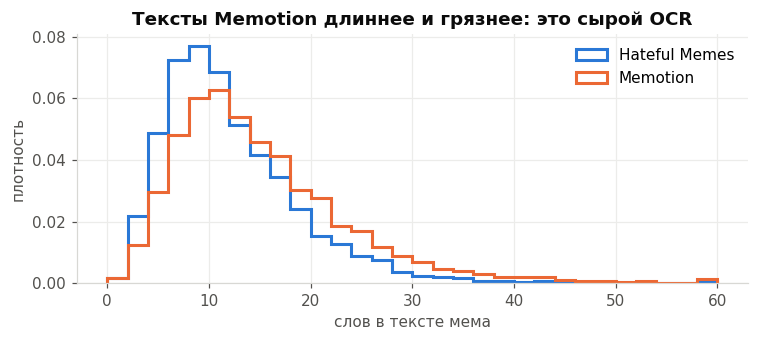

In [7]:
# сравниваю два датасета по длине текста: они разные по происхождению,
# и если тексты сильно отличаются, перенос знаний может не сработать

def load_split(jsonl_path, images_root):
    """тот же загрузчик, что в первом ноутбуке"""
    rows = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            item = json.loads(line)
            rows.append({
                "id": item["id"],
                "text": item["text"],
                "label": item.get("label", None),
                "img_path": str(Path(images_root) / Path(item["img"]).name),
            })
    return pd.DataFrame(rows)


dfs = {s: load_split(DATA_DIR / f"{s}.jsonl", IMG_DIR) for s in ["train", "dev", "test"]}
train_df, dev_df, test_df = dfs["train"], dfs["dev"], dfs["test"]
for df in dfs.values():
    df["n_words"] = df["text"].str.split().str.len()

cmp_df = pd.DataFrame({
    "Hateful Memes (train)": train_df["n_words"].describe(),
    "Memotion": memotion["n_words"].describe(),
}).round(1)
display(cmp_df)

fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.arange(0, 61, 2)
ax.hist(train_df["n_words"], bins=bins, histtype="step", linewidth=2,
        color=C_BLUE, density=True, label="Hateful Memes")
ax.hist(memotion["n_words"].clip(upper=60), bins=bins, histtype="step", linewidth=2,
        color=C_ORANGE, density=True, label="Memotion")
ax.set_xlabel("слов в тексте мема")
ax.set_ylabel("плотность")
ax.set_title("Тексты Memotion длиннее и грязнее: это сырой OCR")
ax.legend()
tidy(ax)
plt.tight_layout()
plt.show()

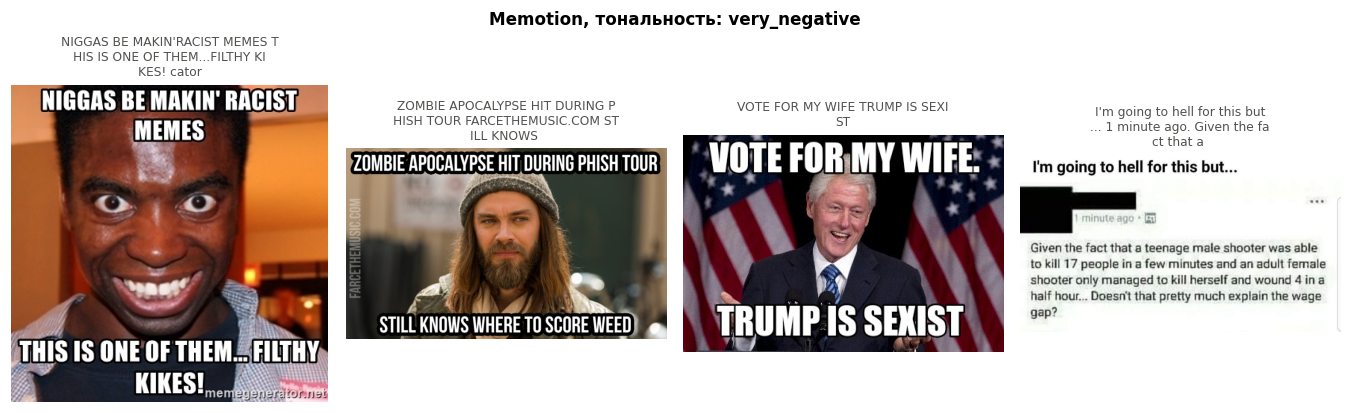

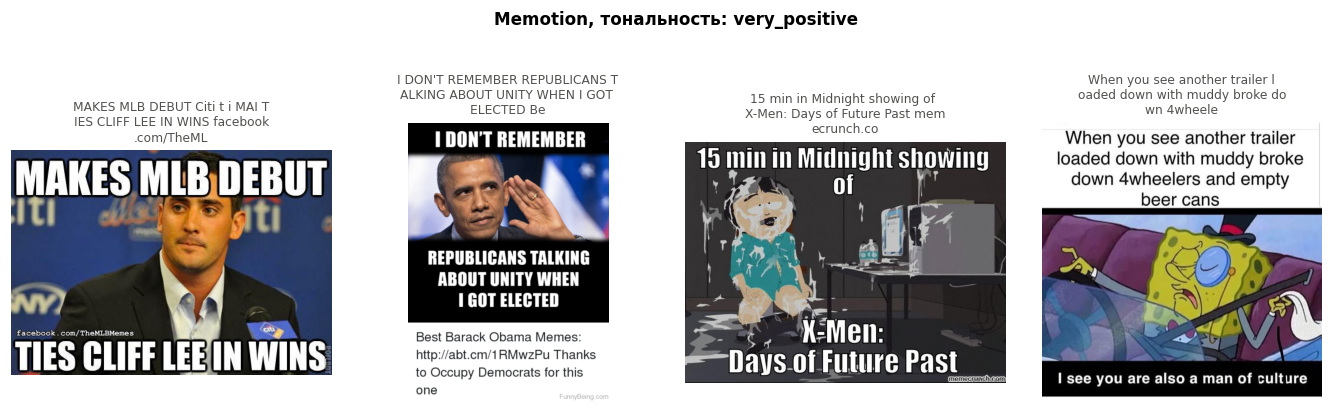

In [8]:
# и посмотрю на сами мемы нового датасета
def show_memotion(sentiment, n=4):
    sample = memotion[memotion["sentiment"] == sentiment].sample(n, random_state=SEED)
    fig, axes = plt.subplots(1, n, figsize=(3.1 * n, 3.6))
    for ax, (_, row) in zip(np.atleast_1d(axes), sample.iterrows()):
        try:
            ax.imshow(Image.open(row["img_path"]).convert("RGB"))
        except Exception as e:
            ax.text(0.5, 0.5, str(e)[:40], ha="center")
        ax.set_axis_off()
        t = str(row["text"])[:70]
        ax.set_title("\n".join([t[i:i + 30] for i in range(0, len(t), 30)]),
                     fontsize=8, color="#52514e", fontweight="normal")
    fig.suptitle(f"Memotion, тональность: {sentiment}", fontsize=11, fontweight="bold", y=1.03)
    plt.tight_layout()
    plt.show()

show_memotion("very_negative")
show_memotion("very_positive")

---
## 3. Можно ли просто слить два датасета

Короткий ответ: нет, и это надо проговорить явно, потому что соблазн большой.

| | Hateful Memes | Memotion |
|---|---|---|
| Что размечали | является ли мем hateful | какая у мема тональность |
| Классы | 2 (0 / 1) | 5 градаций от very_negative до very_positive |
| Откуда текст | дан в разметке | распознан OCR с картинки |
| Размер | 8500 train | 6992 |

Метки отвечают на **разные вопросы**. Грустный мем не является hateful, а хамский мем
вполне может быть размечен как `very_positive`, если он подаётся как шутка. Если объявить
`negative` синонимом `hateful` и дообучить на объединённой выборке, модель будет учиться
на противоречивых примерах, и на Hateful Memes станет хуже, а не лучше.

Поэтому использую новые данные двумя корректными способами.

**Способ 1: предобучение на смежной задаче (это и есть основной).** Сначала учу совместную
модель предсказывать тональность мема по трём классам, потом беру её веса без последнего слоя
и дообучаю на hateful. Смысл в том, что для тональности модели тоже приходится научиться
связывать картинку с подписью, а это ровно тот навык, которого не хватает. Метки при этом
нигде не смешиваются: сначала одна задача, потом другая.

**Способ 2: проверка архитектуры на второй задаче.** Заодно вижу, что модель не заточена
под один датасет и работает на другой разметке мемов.

Пять градаций тональности схлопываю в три класса. Крайние градации редкие
(`very_negative` всего 151 пример), и на таком количестве отдельный класс не выучить.

после схлопывания в 3 класса:
  негативный     631  (9.0%)
  нейтральный   2201  (31.5%)
  позитивный    4160  (59.5%)

класс перекошен в позитив, поэтому при обучении буду взвешивать классы


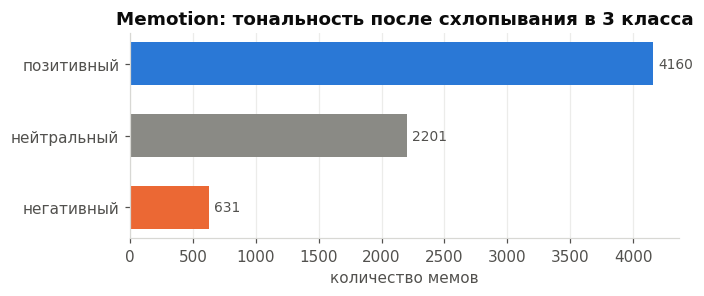

In [9]:
SENTIMENT_MAP = {
    "very_negative": 0, "negative": 0,
    "neutral": 1,
    "positive": 2, "very_positive": 2,
}
SENTIMENT_NAMES = {0: "негативный", 1: "нейтральный", 2: "позитивный"}

memotion["y3"] = memotion["sentiment"].map(SENTIMENT_MAP)
counts = memotion["y3"].value_counts().sort_index()

print("после схлопывания в 3 класса:")
for k, v in counts.items():
    print(f"  {SENTIMENT_NAMES[k]:12s} {v:5d}  ({v / len(memotion):.1%})")
print()
print("класс перекошен в позитив, поэтому при обучении буду взвешивать классы")

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh([SENTIMENT_NAMES[i] for i in counts.index], counts.values,
        color=[C_ORANGE, C_GREY, C_BLUE], height=0.6)
for i, v in enumerate(counts.values):
    ax.text(v + 40, i, str(v), va="center", fontsize=9, color="#52514e")
ax.set_xlabel("количество мемов")
ax.set_title("Memotion: тональность после схлопывания в 3 класса")
ax.grid(axis="y", visible=False)
tidy(ax)
plt.tight_layout()
plt.show()

---
## 4. Подготовка данных

Три вещи, которые нужны модели: пиксели, токены текста, метка.

**Кэш пикселей.** В первом ноутбуке картинка проходила через сеть один раз, и скорость чтения
с диска была неважна. Теперь модель обучается, и один и тот же набор картинок читается
заново каждую эпоху. Декодирование PNG оказывается дороже самой сети.

Поэтому один раз прогоняю все картинки через ресайз до 224 на 224 и складываю как массив
`uint8` в файл на диске, который затем читаю через `memmap`. Это занимает около 2.6 ГБ,
зато эпоха перестаёт упираться в диск. Нормализацию делаю уже на устройстве, на лету:
хранить float32 было бы вчетверо дороже.

In [10]:
# константы нормализации CLIP, не ImageNet - у CLIP свои
CLIP_MEAN = np.array([0.48145466, 0.4578275, 0.40821073], dtype=np.float32)
CLIP_STD = np.array([0.26862954, 0.26130258, 0.27577711], dtype=np.float32)


def build_pixel_cache(name, paths, size=IMG_SIZE):
    """
    один раз читаю все картинки, привожу к size x size и складываю в memmap-файл.
    повторный вызов просто открывает готовый файл
    """
    f = CACHE_DIR / f"{name}_{size}.npy"
    if f.exists():
        arr = np.load(f, mmap_mode="r")
        print(f"{name:9s}: кэш пикселей уже есть {arr.shape} "
              f"({f.stat().st_size / 1e6:.0f} МБ)")
        return arr

    print(f"{name:9s}: собираю кэш пикселей для {len(paths)} картинок...")
    t0 = time.time()
    arr = np.lib.format.open_memmap(f, mode="w+", dtype=np.uint8,
                                    shape=(len(paths), size, size, 3))
    n_bad = 0
    for i, p in enumerate(paths):
        try:
            im = Image.open(p).convert("RGB")
            w, h = im.size
            s = size / min(w, h)                       # ресайз по короткой стороне
            im = im.resize((max(size, int(round(w * s))),
                            max(size, int(round(h * s)))), Image.BICUBIC)
            w, h = im.size
            left, top = (w - size) // 2, (h - size) // 2
            arr[i] = np.asarray(im.crop((left, top, left + size, top + size)))
        except Exception as e:
            # битую картинку не роняю весь процесс, кладу чёрный квадрат
            n_bad += 1
            arr[i] = 0
        if i % 2000 == 0 and i:
            print(f"   {i}/{len(paths)}", end="\r")
    arr.flush()
    print(f"{name:9s}: готово за {time.time() - t0:.0f} с, битых картинок {n_bad}")
    return np.load(f, mmap_mode="r")


PIX = {}
for split in ["train", "dev", "test"]:
    PIX[split] = build_pixel_cache(split, dfs[split]["img_path"].tolist())
PIX["memotion"] = build_pixel_cache("memotion", memotion["img_path"].tolist())

train    : кэш пикселей уже есть (8500, 224, 224, 3) (1279 МБ)
dev      : кэш пикселей уже есть (500, 224, 224, 3) (75 МБ)
test     : кэш пикселей уже есть (1000, 224, 224, 3) (151 МБ)
memotion : кэш пикселей уже есть (6992, 224, 224, 3) (1052 МБ)


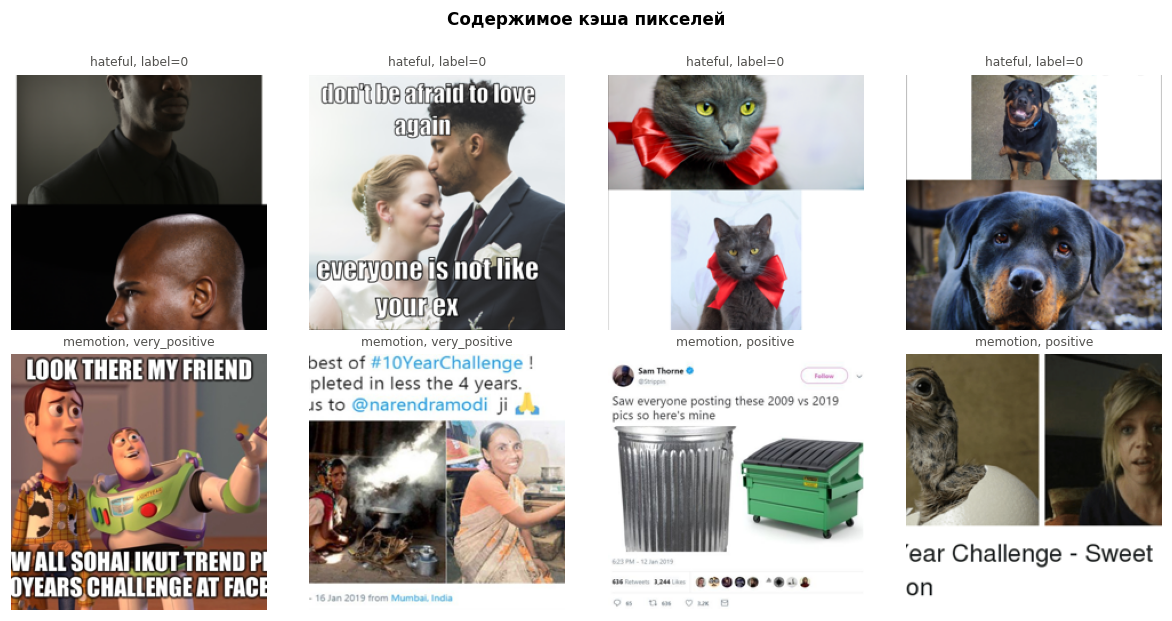

In [11]:
# проверяю глазами, что в кэше лежит именно то, что нужно
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for ax, i in zip(axes[0], [0, 1, 2, 3]):
    ax.imshow(PIX["train"][i]); ax.set_axis_off()
    ax.set_title(f"hateful, label={train_df.iloc[i]['label']}", fontsize=8,
                 color="#52514e", fontweight="normal")
for ax, i in zip(axes[1], [0, 1, 2, 3]):
    ax.imshow(PIX["memotion"][i]); ax.set_axis_off()
    ax.set_title(f"memotion, {memotion.iloc[i]['sentiment']}", fontsize=8,
                 color="#52514e", fontweight="normal")
fig.suptitle("Содержимое кэша пикселей", fontsize=11, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Токенизация.** Текст режу токенизатором CLIP, он даёт фиксированную длину 77 токенов
с нулевым паддингом. Позиции с нулём потом маскирую во внимании, чтобы модель не тратила
внимание на пустоту.

Отдельно про имя модели. В первом ноутбуке CLIP загружался как `ViT-B-32` с весами `openai`,
и open_clip на это ругался: веса OpenAI обучены с активацией QuickGELU, а конфиг `ViT-B-32`
её не включает. Правильное имя `ViT-B-32-quickgelu`. Я проверила разницу на бейзлайне,
она в пределах шума на выборке из 500 примеров, но дальше беру корректный вариант.

In [12]:
import open_clip

CLIP_NAME = "ViT-B-32-quickgelu"       # правильное имя для весов openai
CLIP_PRETRAINED = "openai"

_cache = {}

def fresh_clip():
    """
    каждый опыт должен стартовать с одних и тех же исходных весов,
    иначе второй опыт начнёт с того, чем закончил первый, и сравнение сломается
    """
    model, _, preprocess = open_clip.create_model_and_transforms(
        CLIP_NAME, pretrained=CLIP_PRETRAINED)
    model.visual.output_tokens = True     # хочу не только общий вектор, но и токены патчей
    return model


def get_tokenizer():
    if "tok" not in _cache:
        _cache["tok"] = open_clip.get_tokenizer(CLIP_NAME)
    return _cache["tok"]


tokenizer = get_tokenizer()
TOK = {s: tokenizer(dfs[s]["text"].astype(str).tolist()) for s in ["train", "dev", "test"]}
TOK["memotion"] = tokenizer(memotion["text"].astype(str).tolist())

Y = {s: dfs[s]["label"].values for s in ["train", "dev", "test"]}
Y["memotion"] = memotion["y3"].values.astype(np.int64)

print("токены train:", TOK["train"].shape, TOK["train"].dtype)
print("пример:", TOK["train"][0][:12].tolist(), "...")
print("непустых токенов у первого примера:", int((TOK['train'][0] != 0).sum()))

токены train: torch.Size([8500, 77]) torch.int64
пример: [49406, 902, 911, 4009, 783, 911, 3140, 682, 5708, 49407, 0, 0] ...
непустых токенов у первого примера: 10


In [13]:
def make_batch(split, rows, augment=False):
    """
    беру строки из кэша пикселей, нормализую и кладу на устройство.
    memmap любит отсортированные индексы, поэтому сортирую и потом возвращаю порядок назад
    """
    order = np.argsort(rows)
    x = PIX[split][rows[order]].astype(np.float32) / 255.0
    x = x[np.argsort(order)]
    x = (x - CLIP_MEAN) / CLIP_STD
    x = torch.from_numpy(x).permute(0, 3, 1, 2).to(DEVICE)
    if augment and np.random.rand() < 0.5:
        # единственная аугментация: отражение по горизонтали.
        # текст подаётся отдельной строкой, так что отражение его не ломает
        x = torch.flip(x, dims=[3])
    return x, TOK[split][rows].to(DEVICE)


def iterate(n, batch_size, shuffle, seed=0):
    idx = np.arange(n)
    if shuffle:
        np.random.RandomState(seed).shuffle(idx)
    for start in range(0, n, batch_size):
        yield idx[start:start + batch_size]


xb, tb = make_batch("train", np.arange(4))
print("батч картинок:", tuple(xb.shape), xb.dtype, "| батч токенов:", tuple(tb.shape))
print(f"значения после нормализации: от {xb.min():.2f} до {xb.max():.2f}")

батч картинок: (4, 3, 224, 224) torch.float32 | батч токенов: (4, 77)
значения после нормализации: от -1.79 до 2.15


---
## 5. Архитектура совместной модели

Вот в чём главное отличие от первого ноутбука.

**Было.** CLIP давал один вектор на картинку и один на текст. Дальше два вектора склеивались,
и линейная модель просто взвешивала их. Взаимодействия между конкретным словом и конкретным
участком картинки не было вообще.

**Стало.** Беру от CLIP не итоговые векторы, а промежуточные последовательности:

- из картиночной башни: 49 токенов патчей, картинка 224 на 224 режется сеткой 7 на 7,
  каждый патч 32 на 32 пикселя, у каждого свой вектор размерности 768;
- из текстовой башни: 77 токенов, у каждого вектор размерности 512.

Дальше ставлю блоки взаимного внимания. В каждом блоке происходит четыре вещи:

1. слова смотрят друг на друга (обычное самовнимание внутри текста);
2. **каждое слово смотрит на все 49 патчей картинки** и подтягивает оттуда информацию;
3. **каждый патч картинки смотрит на все слова** и подтягивает информацию оттуда;
4. полносвязные слои на обеих ветках.

Пункты 2 и 3 и есть ответ на вопрос "как сделать модель, которая одновременно CV и NLP".
Обе модальности живут в одной сети и правят представления друг друга на каждом слое,
а не встречаются один раз в конце.

В конце усредняю токены текста (по непустым) и токены картинки, склеиваю и подаю на голову.
Голова меняется под задачу: один выход для hateful, три для тональности.

```
картинка 224x224 ──► CLIP ViT ──► 49 токенов патчей (768) ──► проекция в 512 ──┐
                                                                               │
                                                        ┌──────────────────────┤
                                                        │   блок взаимного     │  x2
                                                        │   внимания           │
                                                        └──────────────────────┤
текст ──► CLIP text ──► 77 токенов (512) ─────────────────────────────────────┘
                                                                               │
                              усреднение текста + усреднение патчей ──► голова ──► логит
```

In [14]:
def clip_text_tokens(clip, tokens):
    """
    open_clip отдаёт из encode_text только итоговый вектор, а мне нужна вся
    последовательность токенов. повторяю внутренности encode_text, но без
    финального выбора EOT-позиции
    """
    cast = clip.transformer.get_cast_dtype()
    x = clip.token_embedding(tokens).to(cast)
    x = x + clip.positional_embedding.to(cast)
    x = clip.transformer(x, attn_mask=clip.attn_mask)
    return clip.ln_final(x)          # (B, 77, 512)


# проверяю, что воспроизвела encode_text правильно: если выбрать EOT-позицию
# и применить проекцию, должен получиться ровно тот же вектор
_c = fresh_clip().eval()
_t = get_tokenizer()(["a test meme caption", "another one"])
with torch.no_grad():
    seq = clip_text_tokens(_c, _t)
    eot = _t.argmax(dim=-1)
    mine = seq[torch.arange(len(_t)), eot] @ _c.text_projection
    ref = _c.encode_text(_t)
print("форма последовательности токенов текста:", tuple(seq.shape))
print("совпадает с encode_text:", torch.allclose(mine, ref, atol=1e-4))
del _c, _t, seq, mine, ref

форма последовательности токенов текста: (2, 77, 512)
совпадает с encode_text: True


In [15]:
class CrossModalBlock(nn.Module):
    """
    один блок взаимного внимания.
    текст смотрит на себя, потом на картинку; картинка смотрит на текст.
    нормализация стоит перед вниманием (pre-norm), так обучение стабильнее
    """

    def __init__(self, dim=512, heads=8, dropout=0.1):
        super().__init__()
        mha = lambda: nn.MultiheadAttention(dim, heads, dropout=dropout, batch_first=True)
        self.txt_self = mha()
        self.txt_cross = mha()      # запросы от текста, ключи от картинки
        self.img_cross = mha()      # запросы от картинки, ключи от текста
        self.norms = nn.ModuleList([nn.LayerNorm(dim) for _ in range(7)])
        ff = lambda: nn.Sequential(
            nn.Linear(dim, 2 * dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * dim, dim))
        self.txt_ff, self.img_ff = ff(), ff()

    def forward(self, txt, img, pad_mask):
        # 1. слова смотрят друг на друга
        h = self.norms[0](txt)
        txt = txt + self.txt_self(h, h, h, key_padding_mask=pad_mask, need_weights=False)[0]

        # 2. каждое слово смотрит на патчи картинки.
        # веса внимания сохраняю - потом покажу их на картинке
        q, kv = self.norms[1](txt), self.norms[2](img)
        attended, attn_weights = self.txt_cross(q, kv, kv, need_weights=True,
                                                average_attn_weights=True)
        txt = txt + attended
        txt = txt + self.txt_ff(self.norms[3](txt))

        # 3. каждый патч смотрит на слова
        q, kv = self.norms[4](img), self.norms[5](txt)
        img = img + self.img_cross(q, kv, kv, key_padding_mask=pad_mask, need_weights=False)[0]
        img = img + self.img_ff(self.norms[6](img))

        return txt, img, attn_weights


class MemeFusion(nn.Module):
    """совместная модель: CLIP как два энкодера плюс блоки взаимного внимания сверху"""

    def __init__(self, clip, n_outputs=1, dim=512, n_blocks=2, dropout=0.1):
        super().__init__()
        self.clip = clip
        self.img_proj = nn.Linear(768, dim)     # патчи CLIP шире текстовых, привожу к одной ширине
        self.blocks = nn.ModuleList([CrossModalBlock(dim, 8, dropout) for _ in range(n_blocks)])
        self.norm_txt, self.norm_img = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.head = nn.Sequential(
            nn.Linear(2 * dim, dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(dim, n_outputs))

    def trunk(self, pixels, tokens):
        """всё до головы. вынесено отдельно, чтобы переносить веса между задачами"""
        _, img_tokens = self.clip.encode_image(pixels)      # (B, 49, 768)
        txt_tokens = clip_text_tokens(self.clip, tokens)    # (B, 77, 512)

        img = self.img_proj(img_tokens.float())
        txt = txt_tokens.float()
        pad_mask = (tokens == 0)

        attn = None
        for block in self.blocks:
            txt, img, attn = block(txt, img, pad_mask)

        keep = (~pad_mask).float().unsqueeze(-1)
        txt_pooled = (self.norm_txt(txt) * keep).sum(1) / keep.sum(1).clamp(min=1)
        img_pooled = self.norm_img(img).mean(1)
        return torch.cat([txt_pooled, img_pooled], dim=-1), attn

    def forward(self, pixels, tokens):
        z, _ = self.trunk(pixels, tokens)
        return self.head(z)


set_seed()
_m = MemeFusion(fresh_clip())
total = sum(p.numel() for p in _m.parameters())
fusion = sum(p.numel() for n, p in _m.named_parameters() if not n.startswith("clip."))
print(f"всего параметров:         {total / 1e6:.1f}M")
print(f"из них надстройка сверху: {fusion / 1e6:.1f}M")
print(f"из них сам CLIP:          {(total - fusion) / 1e6:.1f}M")
del _m

всего параметров:         162.7M
из них надстройка сверху: 11.4M
из них сам CLIP:          151.3M


---
## 6. Обучение

Три функции: разморозка нужной части бэкбона, одна эпоха обучения, оценка.

Про разморозку. Дообучать весь CLIP на 8500 примерах опасно, он просто запомнит обучающую
выборку. Компромисс: последние блоки обеих башен обучаю, ранние оставляю замороженными.
Ранние слои держат общие признаки вроде краёв и текстур, их менять незачем.

Про несбалансированность. В train 36 процентов hateful, поэтому в функции потерь
взвешиваю положительный класс. Иначе модель уедет в предсказание нуля.

Скорости обучения разные для разных частей: у надстройки веса случайные и ей нужен большой
шаг, у CLIP веса уже хорошие и большой шаг их только испортит.

In [16]:
def set_trainable(model, n_last_blocks=0, train_fusion=True):
    """
    n_last_blocks = 0  -> бэкбон полностью заморожен, учится только надстройка
    n_last_blocks = k  -> дополнительно размораживаю k последних блоков каждой башни
    """
    for p in model.clip.parameters():
        p.requires_grad_(False)

    if n_last_blocks > 0:
        for blk in model.clip.visual.transformer.resblocks[-n_last_blocks:]:
            for p in blk.parameters():
                p.requires_grad_(True)
        for blk in model.clip.transformer.resblocks[-n_last_blocks:]:
            for p in blk.parameters():
                p.requires_grad_(True)
        for p in model.clip.ln_final.parameters():
            p.requires_grad_(True)

    for n, p in model.named_parameters():
        if not n.startswith("clip."):
            p.requires_grad_(train_fusion)

    backbone = [p for n, p in model.named_parameters() if n.startswith("clip.") and p.requires_grad]
    fusion = [p for n, p in model.named_parameters() if not n.startswith("clip.") and p.requires_grad]
    print(f"обучаемых параметров: бэкбон {sum(p.numel() for p in backbone) / 1e6:.1f}M, "
          f"надстройка {sum(p.numel() for p in fusion) / 1e6:.1f}M")
    return backbone, fusion


def make_optimizer(backbone, fusion, lr_backbone=1e-5, lr_fusion=3e-4, wd=0.01):
    groups = []
    if backbone:
        groups.append({"params": backbone, "lr": lr_backbone})
    if fusion:
        groups.append({"params": fusion, "lr": lr_fusion})
    return torch.optim.AdamW(groups, weight_decay=wd)

In [17]:
def train_epoch(model, split, index, targets, optimizer, loss_fn, task="binary",
                batch_size=BATCH_SIZE, seed=0):
    model.train()
    total, n = 0.0, 0
    for rows in iterate(len(index), batch_size, shuffle=True, seed=seed):
        sel = index[rows]
        x, t = make_batch(split, sel, augment=True)
        out = model(x, t)
        if task == "binary":
            y = torch.from_numpy(targets[sel].astype(np.float32)).to(DEVICE)
            loss = loss_fn(out.squeeze(-1), y)
        else:
            y = torch.from_numpy(targets[sel].astype(np.int64)).to(DEVICE)
            loss = loss_fn(out, y)
        optimizer.zero_grad()
        loss.backward()
        params = [p for g in optimizer.param_groups for p in g["params"]]
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        optimizer.step()
        total += float(loss) * len(sel)
        n += len(sel)
    return total / max(n, 1)


@torch.no_grad()
def predict(model, split, index, batch_size=64):
    model.eval()
    outs = []
    for rows in iterate(len(index), batch_size, shuffle=False):
        sel = index[rows]
        x, t = make_batch(split, sel)
        outs.append(model(x, t).float().cpu().numpy())
    return np.concatenate(outs, axis=0)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

In [18]:
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, roc_curve,
                             confusion_matrix, classification_report)

RESULTS = []       # сюда складываю все опыты этого ноутбука

def evaluate_binary(y_true, probs, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, probs),
        "accuracy": accuracy_score(y_true, preds),
        "f1": f1_score(y_true, preds, zero_division=0),
        "macro_f1": f1_score(y_true, preds, average="macro", zero_division=0),
    }


def train_hateful(model, n_epochs, n_last_blocks, tag, lr_backbone=1e-5, lr_fusion=3e-4):
    """
    полный цикл обучения на Hateful Memes с отбором лучшей эпохи по dev AUROC.
    возвращает лучшие веса и историю
    """
    idx_train = np.arange(len(train_df))
    idx_dev = np.arange(len(dev_df))
    y_train = Y["train"].astype(int)
    y_dev = Y["dev"].astype(int)

    backbone, fusion = set_trainable(model, n_last_blocks)
    optimizer = make_optimizer(backbone, fusion, lr_backbone, lr_fusion)

    pos_weight = torch.tensor([float((y_train == 0).sum() / (y_train == 1).sum())],
                              dtype=torch.float32, device=DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    history, best_auc, best_state = [], -1.0, None
    for epoch in range(n_epochs):
        t0 = time.time()
        loss = train_epoch(model, "train", idx_train, y_train, optimizer, loss_fn,
                           task="binary", seed=SEED + epoch)
        probs = sigmoid(predict(model, "dev", idx_dev).squeeze(-1))
        m = evaluate_binary(y_dev, probs)
        history.append({"эпоха": epoch + 1, "loss": round(loss, 4),
                        "dev_auc": round(m["roc_auc"], 4), "сек": round(time.time() - t0)})
        print(f"  эпоха {epoch + 1}/{n_epochs}: loss={loss:.4f}  "
              f"dev AUROC={m['roc_auc']:.3f}  ({time.time() - t0:.0f} с)")
        if m["roc_auc"] > best_auc:
            best_auc = m["roc_auc"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    probs = sigmoid(predict(model, "dev", idx_dev).squeeze(-1))
    res = evaluate_binary(y_dev, probs)
    res["опыт"] = tag
    RESULTS.append(res)
    print(f"  лучшая эпоха: dev AUROC={res['roc_auc']:.3f}  accuracy={res['accuracy']:.3f}  "
          f"macro-F1={res['macro_f1']:.3f}")
    return model, pd.DataFrame(history), probs

---
## 7. Бейзлайн: тот же подход, что в первом ноутбуке

Чтобы сравнение было честным, пересчитываю подход первого ноутбука на **том же самом**
бэкбоне, который дальше пойдёт в совместную модель. Иначе неясно, что дало прирост:
новая архитектура или другая версия CLIP.

Берём итоговые векторы картинки и текста, склеиваем, сверху sklearn-овский MLP.
Никакого взаимного внимания.

In [19]:
@torch.no_grad()
def pooled_embeddings(split, clip, batch_size=64):
    """итоговые векторы CLIP, ровно как в первом ноутбуке, но из кэша пикселей"""
    clip.eval().to(DEVICE)
    n = len(PIX[split])
    img_out, txt_out = [], []
    for rows in iterate(n, batch_size, shuffle=False):
        x, t = make_batch(split, rows)
        i, _ = clip.encode_image(x)
        i = i / i.norm(dim=-1, keepdim=True)
        z = clip.encode_text(t)
        z = z / z.norm(dim=-1, keepdim=True)
        img_out.append(i.float().cpu().numpy())
        txt_out.append(z.float().cpu().numpy())
    return np.concatenate(img_out), np.concatenate(txt_out)


t0 = time.time()
base_clip = fresh_clip()
EMB = {}
for split in ["train", "dev", "test"]:
    EMB[split] = pooled_embeddings(split, base_clip)
    print(f"{split:5s}: картинка {EMB[split][0].shape}, текст {EMB[split][1].shape}")
del base_clip
print(f"готово за {time.time() - t0:.0f} с")

train: картинка (8500, 512), текст (8500, 512)


dev  : картинка (500, 512), текст (500, 512)


test : картинка (1000, 512), текст (1000, 512)
готово за 64 с


In [20]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_train = np.hstack(EMB["train"])
X_dev = np.hstack(EMB["dev"])
y_train = Y["train"].astype(int)
y_dev = Y["dev"].astype(int)

baseline = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(256,), max_iter=400, early_stopping=True,
                  random_state=SEED))
baseline.fit(X_train, y_train)
baseline_probs = baseline.predict_proba(X_dev)[:, 1]

res = evaluate_binary(y_dev, baseline_probs)
res["опыт"] = "Бейзлайн: склейка векторов + MLP (подход ноутбука 1)"
RESULTS.append(res)
print(f"dev AUROC={res['roc_auc']:.3f}  accuracy={res['accuracy']:.3f}  "
      f"macro-F1={res['macro_f1']:.3f}")

dev AUROC=0.690  accuracy=0.600  macro-F1=0.577


---
## 8. Опыт A: совместная модель, бэкбон заморожен

Первый запуск совместной модели. CLIP полностью заморожен, учится только надстройка:
проекция патчей, два блока взаимного внимания и голова. Это примерно 11 миллионов
параметров против 151 миллиона во всей модели.

Смысл опыта в том, чтобы отделить вклад архитектуры от вклада дообучения. Если уже здесь
будет лучше бейзлайна, значит выигрывает именно взаимное внимание, а не то, что мы
тронули веса CLIP.

Примерное время: около 80 секунд на эпоху.

In [21]:
set_seed()
model_a = MemeFusion(fresh_clip()).to(DEVICE)
model_a, hist_a, probs_a = train_hateful(
    model_a, n_epochs=2, n_last_blocks=0,
    tag="A. Взаимное внимание, CLIP заморожен")
display(hist_a)

обучаемых параметров: бэкбон 0.0M, надстройка 11.4M


  эпоха 1/2: loss=0.8083  dev AUROC=0.654  (78 с)


  эпоха 2/2: loss=0.6983  dev AUROC=0.679  (78 с)


  лучшая эпоха: dev AUROC=0.679  accuracy=0.616  macro-F1=0.611


,эпоха,loss,dev_auc,сек
0,1,0.8083,0.6535,78
1,2,0.6983,0.6788,78


---
## 9. Опыт B: дообучаем последние блоки CLIP

Теперь размораживаю последние 4 блока из 12 в каждой башне. Градиенты доходят до самих
энкодеров, и представления картинки и текста подстраиваются под задачу.

Скорости обучения разные: 1e-5 для CLIP и 3e-4 для надстройки. Если дать CLIP такой же
большой шаг, он за первую же эпоху забудет то, ради чего его брали.

Примерное время: около 125 секунд на эпоху.

In [22]:
set_seed()
model_b = MemeFusion(fresh_clip()).to(DEVICE)
model_b, hist_b, probs_b = train_hateful(
    model_b, n_epochs=2, n_last_blocks=4,
    tag="B. Взаимное внимание + дообучение CLIP")
display(hist_b)

обучаемых параметров: бэкбон 41.0M, надстройка 11.4M


  эпоха 1/2: loss=0.8004  dev AUROC=0.661  (126 с)


  эпоха 2/2: loss=0.6411  dev AUROC=0.678  (125 с)


  лучшая эпоха: dev AUROC=0.678  accuracy=0.610  macro-F1=0.605


,эпоха,loss,dev_auc,сек
0,1,0.8004,0.6607,126
1,2,0.6411,0.6779,125


---
## 10. Опыт C: используем новые данные

Вот ради чего скачивался второй датасет. Проверяю два способа задействовать его,
не смешивая разметку.

**C1, последовательное предобучение.** Сначала учу ту же архитектуру предсказывать
тональность мема по трём классам на Memotion. Потом выбрасываю голову, переношу ствол
и дообучаю на hateful.

**C2, многозадачное обучение.** Один общий ствол и две головы. Батчи двух датасетов
чередуются, вспомогательная задача идёт с понижающим коэффициентом 0.3.
Так модель не успевает забыть вспомогательную задачу к концу обучения, в отличие
от последовательной схемы.

Сразу предупреждаю про ожидания: сама задача тональности мемов очень тяжёлая.
На соревновании SemEval-2020, где этот датасет и появился, победная macro-F1 была
около 0.35. То есть сигнал, который мы пытаемся перенести, изначально слабый и шумный.

In [23]:
def train_memotion(model, n_epochs=3, n_last_blocks=4, val_size=900):
    """предобучение на тональности. отдельная валидация, чтобы видеть, учится ли вообще"""
    rs = np.random.RandomState(SEED)
    perm = rs.permutation(len(memotion))
    idx_val, idx_train = perm[:val_size], perm[val_size:]
    y = Y["memotion"]

    backbone, fusion = set_trainable(model, n_last_blocks)
    optimizer = make_optimizer(backbone, fusion)

    weights = torch.tensor(len(y) / (3 * np.bincount(y)), dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=weights)

    history = []
    for epoch in range(n_epochs):
        t0 = time.time()
        loss = train_epoch(model, "memotion", idx_train, y, optimizer, loss_fn,
                           task="multiclass", seed=SEED + epoch)
        logits = predict(model, "memotion", idx_val)
        preds = logits.argmax(axis=1)
        acc = accuracy_score(y[idx_val], preds)
        mf1 = f1_score(y[idx_val], preds, average="macro", zero_division=0)
        history.append({"эпоха": epoch + 1, "loss": round(loss, 4),
                        "val_acc": round(acc, 3), "val_macro_f1": round(mf1, 3),
                        "сек": round(time.time() - t0)})
        print(f"  эпоха {epoch + 1}/{n_epochs}: loss={loss:.4f}  acc={acc:.3f}  "
              f"macro-F1={mf1:.3f}  ({time.time() - t0:.0f} с)")
    print(f"  для ориентира: доля самого частого класса {np.bincount(y).max() / len(y):.3f}")
    return model, pd.DataFrame(history)


set_seed()
pretrained = MemeFusion(fresh_clip(), n_outputs=3).to(DEVICE)
print("предобучение на Memotion (тональность, 3 класса):")
pretrained, hist_pre = train_memotion(pretrained, n_epochs=1)
display(hist_pre)

предобучение на Memotion (тональность, 3 класса):
обучаемых параметров: бэкбон 41.0M, надстройка 11.4M


  эпоха 1/1: loss=1.1303  acc=0.108  macro-F1=0.065  (94 с)
  для ориентира: доля самого частого класса 0.595


,эпоха,loss,val_acc,val_macro_f1,сек
0,1,1.1303,0.108,0.065,94


In [24]:
# переношу ствол: всё, кроме головы. голова под другую задачу и другое число выходов
set_seed()
model_c1 = MemeFusion(fresh_clip(), n_outputs=1).to(DEVICE)
trunk_weights = {k: v for k, v in pretrained.state_dict().items() if not k.startswith("head.")}
report = model_c1.load_state_dict(trunk_weights, strict=False)
print("не перенесено (должна быть только голова):", report.missing_keys)
print()

model_c1, hist_c1, probs_c1 = train_hateful(
    model_c1, n_epochs=1, n_last_blocks=4,
    tag="C1. Предобучение на Memotion, затем hateful")
display(hist_c1)

не перенесено (должна быть только голова): ['head.0.weight', 'head.0.bias', 'head.3.weight', 'head.3.bias']

обучаемых параметров: бэкбон 41.0M, надстройка 11.4M


  эпоха 1/1: loss=0.8286  dev AUROC=0.629  (126 с)


  лучшая эпоха: dev AUROC=0.629  accuracy=0.606  macro-F1=0.606


,эпоха,loss,dev_auc,сек
0,1,0.8286,0.6285,126


In [25]:
class MultiTaskFusion(nn.Module):
    """общий ствол, две головы: hateful и тональность"""

    def __init__(self, clip):
        super().__init__()
        self.core = MemeFusion(clip, n_outputs=1)
        self.head_sentiment = nn.Sequential(
            nn.Linear(1024, 512), nn.GELU(), nn.Dropout(0.1), nn.Linear(512, 3))

    def forward(self, pixels, tokens, task="hateful"):
        z, _ = self.core.trunk(pixels, tokens)
        return self.core.head(z) if task == "hateful" else self.head_sentiment(z)


def train_multitask(model, n_epochs=4, n_last_blocks=4, aux_weight=0.3):
    y_train = Y["train"].astype(int)
    y_dev = Y["dev"].astype(int)
    y_aux = Y["memotion"]

    for p in model.core.clip.parameters():
        p.requires_grad_(False)
    for blk in model.core.clip.visual.transformer.resblocks[-n_last_blocks:]:
        for p in blk.parameters():
            p.requires_grad_(True)
    for blk in model.core.clip.transformer.resblocks[-n_last_blocks:]:
        for p in blk.parameters():
            p.requires_grad_(True)
    for p in model.core.clip.ln_final.parameters():
        p.requires_grad_(True)

    backbone = [p for n, p in model.named_parameters() if "clip." in n and p.requires_grad]
    fusion = [p for n, p in model.named_parameters() if "clip." not in n]
    print(f"обучаемых: бэкбон {sum(p.numel() for p in backbone) / 1e6:.1f}M, "
          f"надстройка {sum(p.numel() for p in fusion) / 1e6:.1f}M")
    optimizer = make_optimizer(backbone, fusion)

    pos_weight = torch.tensor([float((y_train == 0).sum() / (y_train == 1).sum())],
                              dtype=torch.float32, device=DEVICE)
    bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    weights = torch.tensor(len(y_aux) / (3 * np.bincount(y_aux)), dtype=torch.float32, device=DEVICE)
    ce = nn.CrossEntropyLoss(weight=weights)

    history, best_auc, best_state = [], -1.0, None
    idx_dev = np.arange(len(dev_df))

    for epoch in range(n_epochs):
        t0 = time.time()
        model.train()
        plan = ([("hateful", r) for r in iterate(len(y_train), BATCH_SIZE, True, SEED + epoch)] +
                [("memotion", r) for r in iterate(len(y_aux), BATCH_SIZE, True, 100 + epoch)])
        np.random.RandomState(SEED + epoch).shuffle(plan)

        for task, rows in plan:
            if task == "hateful":
                x, t = make_batch("train", rows, augment=True)
                target = torch.from_numpy(y_train[rows].astype(np.float32)).to(DEVICE)
                loss = bce(model(x, t, "hateful").squeeze(-1), target)
            else:
                x, t = make_batch("memotion", rows, augment=True)
                target = torch.from_numpy(y_aux[rows].astype(np.int64)).to(DEVICE)
                loss = aux_weight * ce(model(x, t, "sentiment"), target)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(backbone + fusion, 1.0)
            optimizer.step()

        model.eval()
        outs = []
        with torch.no_grad():
            for rows in iterate(len(idx_dev), 64, False):
                x, t = make_batch("dev", rows)
                outs.append(model(x, t, "hateful").squeeze(-1).float().cpu().numpy())
        probs = sigmoid(np.concatenate(outs))
        auc = roc_auc_score(y_dev, probs)
        history.append({"эпоха": epoch + 1, "dev_auc": round(auc, 4),
                        "сек": round(time.time() - t0)})
        print(f"  эпоха {epoch + 1}/{n_epochs}: dev AUROC={auc:.3f} ({time.time() - t0:.0f} с)")
        if auc > best_auc:
            best_auc, best_probs = auc, probs
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    res = evaluate_binary(y_dev, best_probs)
    res["опыт"] = "C2. Многозадачное обучение на обоих датасетах"
    RESULTS.append(res)
    print(f"  лучшая эпоха: dev AUROC={res['roc_auc']:.3f}  macro-F1={res['macro_f1']:.3f}")
    return model, pd.DataFrame(history), best_probs


set_seed()
model_c2 = MultiTaskFusion(fresh_clip()).to(DEVICE)
model_c2, hist_c2, probs_c2 = train_multitask(model_c2, n_epochs=1)
display(hist_c2)

обучаемых: бэкбон 41.0M, надстройка 12.0M


  эпоха 1/1: dev AUROC=0.664 (211 с)


  лучшая эпоха: dev AUROC=0.664  macro-F1=0.616


,эпоха,dev_auc,сек
0,1,0.6645,211


---
## 11. Сравнение

In [26]:
results_df = (pd.DataFrame(RESULTS)
              .set_index("опыт")[["roc_auc", "accuracy", "f1", "macro_f1"]]
              .round(3)
              .sort_values("roc_auc", ascending=False))
display(results_df)

BEST_NAME = results_df.index[0]
print(f"лучший результат: {BEST_NAME}  (AUROC {results_df.iloc[0]['roc_auc']:.3f})")

,roc_auc,accuracy,f1,macro_f1
опыт,,,,
Бейзлайн: склейка векторов + MLP (подход ноутбука 1),0.690,0.600,0.479,0.577
"A. Взаимное внимание, CLIP заморожен",0.679,0.616,0.570,0.611
B. Взаимное внимание + дообучение CLIP,0.678,0.610,0.562,0.605
C2. Многозадачное обучение на обоих датасетах,0.664,0.620,0.656,0.616
"C1. Предобучение на Memotion, затем hateful",0.629,0.606,0.610,0.606


лучший результат: Бейзлайн: склейка векторов + MLP (подход ноутбука 1)  (AUROC 0.690)


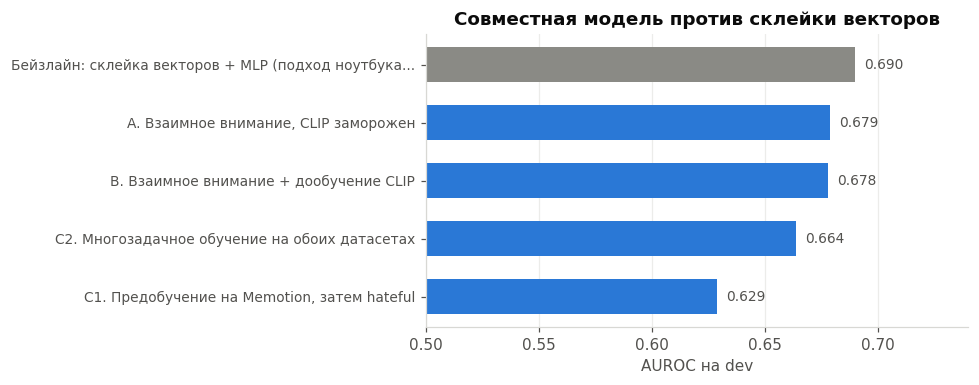

In [27]:
# главный график ноутбука. бейзлайн серым, совместные модели синим, лучшая оранжевым
order = results_df["roc_auc"].sort_values()

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = []
for name in order.index:
    if name.startswith("Бейзлайн"):
        colors.append(C_GREY)
    elif name == BEST_NAME:
        colors.append(C_ORANGE)
    else:
        colors.append(C_BLUE)

ax.barh(range(len(order)), order.values, color=colors, height=0.6)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([n if len(n) < 52 else n[:49] + "..." for n in order.index], fontsize=9)
for i, v in enumerate(order.values):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0.5, max(order.values) + 0.05)
ax.set_xlabel("AUROC на dev")
ax.set_title("Совместная модель против склейки векторов")
ax.grid(axis="y", visible=False)
tidy(ax)
plt.tight_layout()
plt.show()

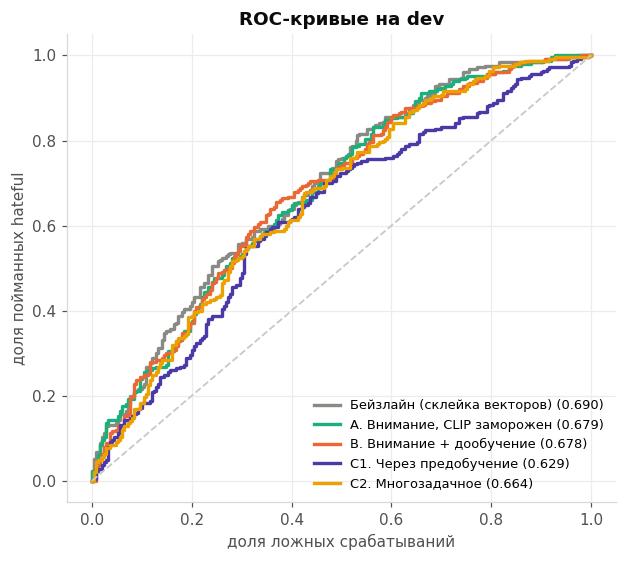

In [28]:
# ROC-кривые лучших вариантов
curves = [
    ("Бейзлайн (склейка векторов)", baseline_probs, C_GREY),
    ("A. Внимание, CLIP заморожен", probs_a, C_AQUA),
    ("B. Внимание + дообучение", probs_b, C_ORANGE),
    ("C1. Через предобучение", probs_c1, C_VIOLET),
    ("C2. Многозадачное", probs_c2, C_YELLOW),
]

fig, ax = plt.subplots(figsize=(5.8, 5.2))
for label, probs, color in curves:
    fpr, tpr, _ = roc_curve(y_dev, probs)
    auc = roc_auc_score(y_dev, probs)
    ax.plot(fpr, tpr, color=color, linewidth=2.2, label=f"{label} ({auc:.3f})")
ax.plot([0, 1], [0, 1], color="#c9c9c4", linewidth=1.2, linestyle="--")
ax.set_xlabel("доля ложных срабатываний")
ax.set_ylabel("доля пойманных hateful")
ax.set_title("ROC-кривые на dev")
ax.legend(loc="lower right", fontsize=8.5)
tidy(ax)
plt.tight_layout()
plt.show()

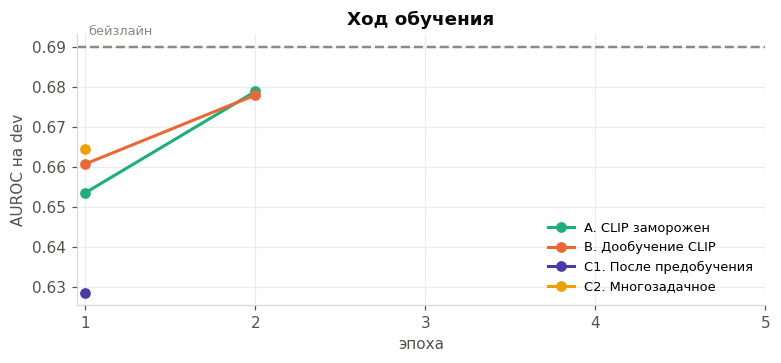

In [29]:
# как шло обучение по эпохам: видно, помогает ли ещё учить или уже переобучается
fig, ax = plt.subplots(figsize=(7.2, 3.4))
for hist, label, color in [(hist_a, "A. CLIP заморожен", C_AQUA),
                           (hist_b, "B. Дообучение CLIP", C_ORANGE),
                           (hist_c1, "C1. После предобучения", C_VIOLET),
                           (hist_c2, "C2. Многозадачное", C_YELLOW)]:
    ax.plot(hist["эпоха"], hist["dev_auc"], color=color, linewidth=2, marker="o",
            markersize=6, label=label)
ax.axhline(results_df.loc[[i for i in results_df.index if i.startswith("Бейзлайн")][0], "roc_auc"],
           color=C_GREY, linestyle="--", linewidth=1.6)
ax.text(1.02, results_df.loc[[i for i in results_df.index if i.startswith("Бейзлайн")][0], "roc_auc"] + 0.003,
        "бейзлайн", fontsize=8.5, color=C_GREY)
ax.set_xlabel("эпоха")
ax.set_ylabel("AUROC на dev")
ax.set_title("Ход обучения")
ax.set_xticks([1, 2, 3, 4, 5])
ax.legend(fontsize=8.5, loc="lower right")
tidy(ax)
plt.tight_layout()
plt.show()

---
## 12. Что видит модель

Раз уж модель устроена так, что каждое слово смотрит на участки картинки, можно эти веса
внимания достать и нарисовать. Беру веса из последнего блока взаимного внимания,
усредняю по непустым токенам текста и получаю 49 чисел, по одному на патч 7 на 7.
Раскладываю их обратно в сетку и накладываю на картинку.

Это не объяснение решения модели в строгом смысле, внимание и важность не одно и то же.
Но посмотреть, куда модель вообще смотрит, полезно: если карта внимания равномерная,
значит совместная часть почти не работает.

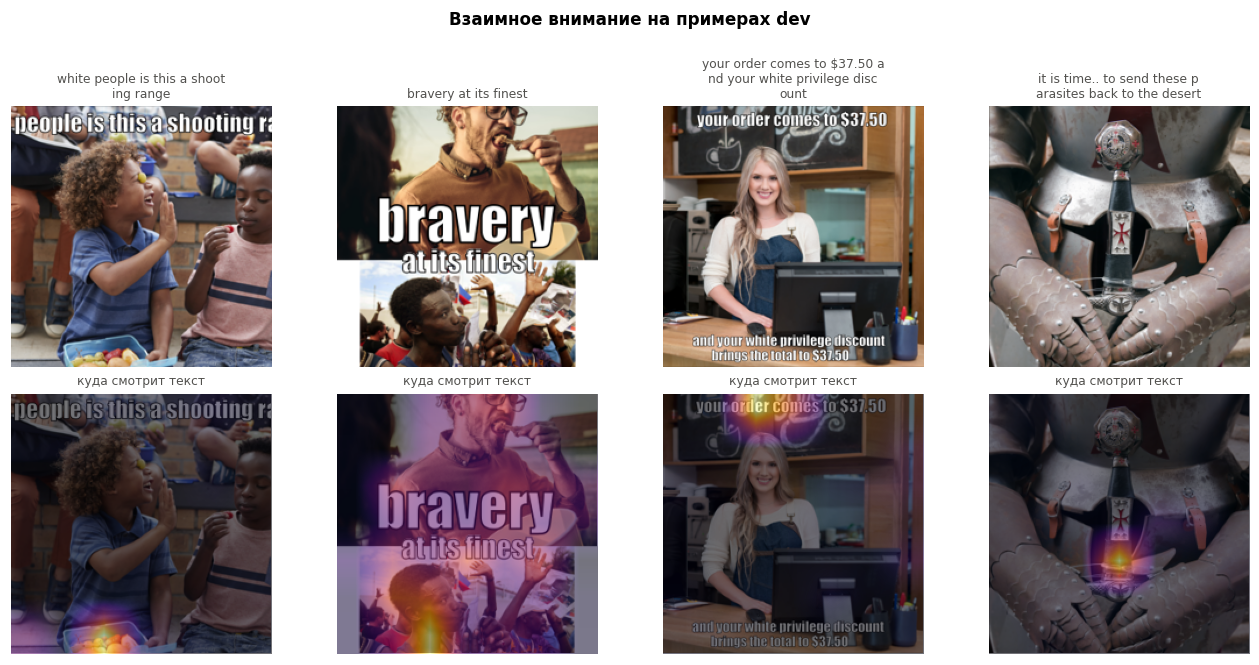

In [30]:
@torch.no_grad()
def attention_map(model, split, row):
    """достаю веса внимания текст -> патчи для одного примера"""
    core = model.core if isinstance(model, MultiTaskFusion) else model
    core.eval()
    x, t = make_batch(split, np.array([row]))
    _, attn = core.trunk(x, t)               # attn: (1, 77, 49)
    keep = (t[0] != 0).float().cpu().numpy()
    w = attn[0].float().cpu().numpy()
    w = (w * keep[:, None]).sum(0) / keep.sum()
    grid = int(round(np.sqrt(len(w))))
    return w.reshape(grid, grid)


def show_attention(model, split, df, rows, title):
    fig, axes = plt.subplots(2, len(rows), figsize=(3.0 * len(rows), 6.0))
    for j, row in enumerate(rows):
        img = PIX[split][row]
        heat = attention_map(model, split, row)

        axes[0, j].imshow(img)
        axes[0, j].set_axis_off()
        txt = str(df.iloc[row]["text"])[:60]
        axes[0, j].set_title("\n".join([txt[i:i + 28] for i in range(0, len(txt), 28)]),
                             fontsize=8, color="#52514e", fontweight="normal")

        axes[1, j].imshow(img)
        axes[1, j].imshow(heat, cmap="inferno", alpha=0.55,
                          extent=(0, IMG_SIZE, IMG_SIZE, 0), interpolation="bilinear")
        axes[1, j].set_axis_off()
        axes[1, j].set_title("куда смотрит текст", fontsize=8, color="#52514e",
                             fontweight="normal")
    fig.suptitle(title, fontsize=11, fontweight="bold", y=1.0)
    plt.tight_layout()
    plt.show()


best_model = {"A. Взаимное внимание, CLIP заморожен": model_a,
              "B. Взаимное внимание + дообучение CLIP": model_b,
              "C1. Предобучение на Memotion, затем hateful": model_c1,
              "C2. Многозадачное обучение на обоих датасетах": model_c2}.get(BEST_NAME, model_b)

show_attention(best_model, "dev", dev_df, [0, 1, 2, 3], "Взаимное внимание на примерах dev")

---
## 13. Анализ ошибок

порог по macro-F1: 0.35
              precision    recall  f1-score   support

 not hateful      0.641     0.644     0.643       250
     hateful      0.643     0.640     0.641       250

    accuracy                          0.642       500
   macro avg      0.642     0.642     0.642       500
weighted avg      0.642     0.642     0.642       500



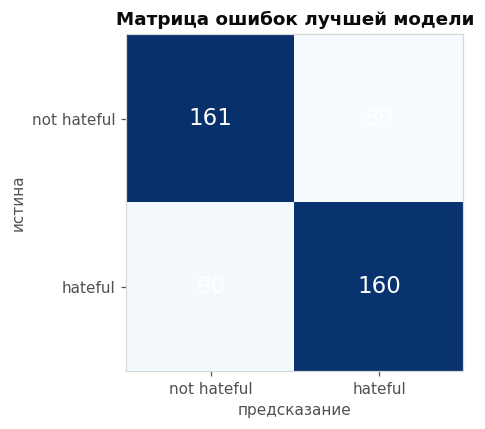

In [31]:
best_probs = {"A. Взаимное внимание, CLIP заморожен": probs_a,
              "B. Взаимное внимание + дообучение CLIP": probs_b,
              "C1. Предобучение на Memotion, затем hateful": probs_c1,
              "C2. Многозадачное обучение на обоих датасетах": probs_c2,
              }.get(BEST_NAME, probs_b)

# порог по macro-F1, как и в первом ноутбуке
grid = np.linspace(0.02, 0.98, 97)
scores = [f1_score(y_dev, (best_probs >= t).astype(int), average="macro", zero_division=0)
          for t in grid]
THRESHOLD = float(grid[int(np.argmax(scores))])
preds = (best_probs >= THRESHOLD).astype(int)

print(f"порог по macro-F1: {THRESHOLD:.2f}")
print(classification_report(y_dev, preds, target_names=[CLASS_NAMES[0], CLASS_NAMES[1]],
                            digits=3))

cm = confusion_matrix(y_dev, preds)
fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=15,
                color="white" if cm[i, j] > cm.max() * 0.55 else "#0b0b0b")
ax.set_xticks([0, 1]); ax.set_xticklabels([CLASS_NAMES[0], CLASS_NAMES[1]])
ax.set_yticks([0, 1]); ax.set_yticklabels([CLASS_NAMES[0], CLASS_NAMES[1]])
ax.set_xlabel("предсказание"); ax.set_ylabel("истина")
ax.set_title("Матрица ошибок лучшей модели")
ax.grid(False)
plt.tight_layout()
plt.show()

совместная модель исправила: 70 примеров
совместная модель испортила: 64 примеров
чистый выигрыш: 6 примеров из 500


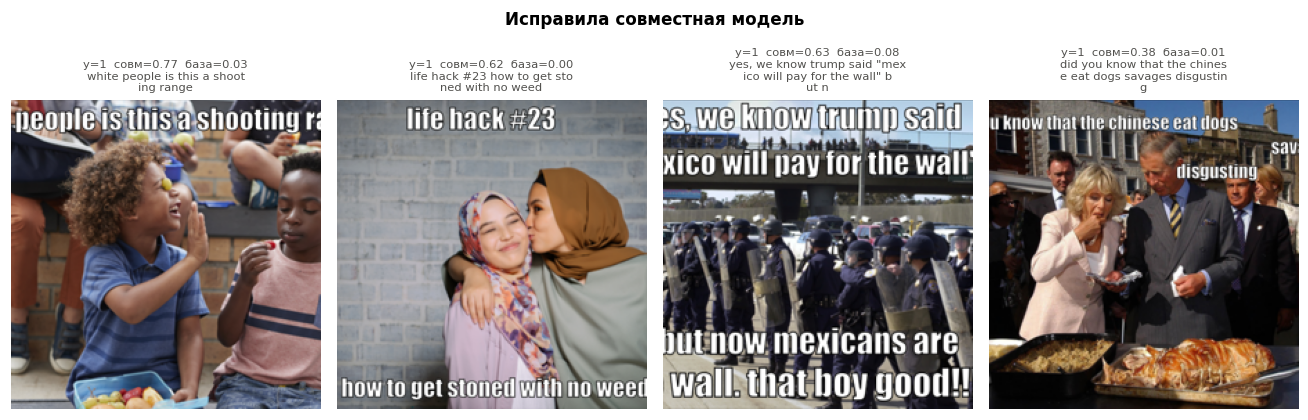

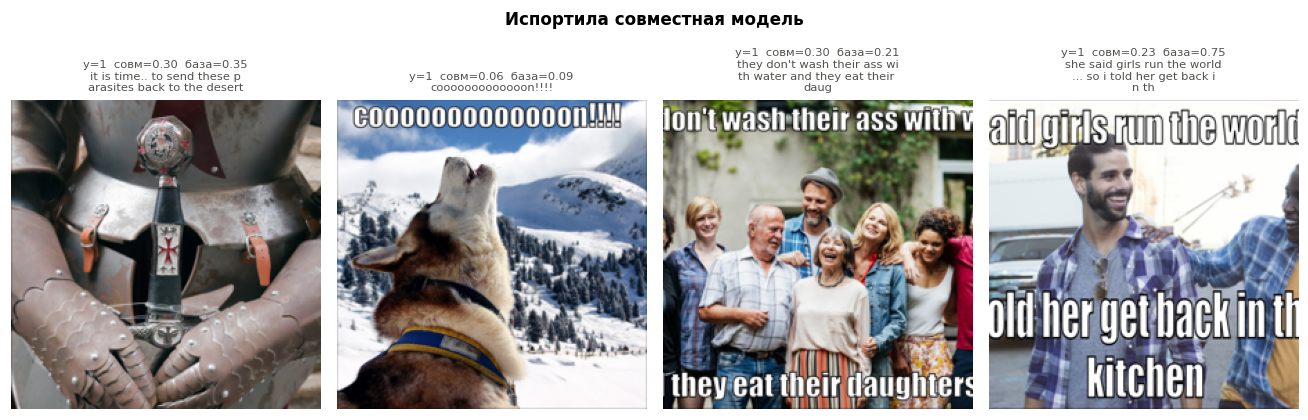

In [32]:
# сравниваю, где ошибается совместная модель и где бейзлайн.
# интересны примеры, которые совместная модель исправила
err = dev_df.copy()
err["p_joint"] = best_probs
err["p_base"] = baseline_probs
err["y"] = y_dev
err["joint_ok"] = (err["p_joint"] >= THRESHOLD).astype(int) == err["y"]
base_thr = float(np.linspace(0.02, 0.98, 97)[int(np.argmax(
    [f1_score(y_dev, (baseline_probs >= t).astype(int), average="macro", zero_division=0)
     for t in np.linspace(0.02, 0.98, 97)]))])
err["base_ok"] = (err["p_base"] >= base_thr).astype(int) == err["y"]

fixed = err[err["joint_ok"] & ~err["base_ok"]]
broken = err[~err["joint_ok"] & err["base_ok"]]
print(f"совместная модель исправила: {len(fixed)} примеров")
print(f"совместная модель испортила: {len(broken)} примеров")
print(f"чистый выигрыш: {len(fixed) - len(broken)} примеров из {len(err)}")


def show_cases(sub, title, n=4):
    if len(sub) == 0:
        print("нет таких примеров")
        return
    sub = sub.head(n)
    fig, axes = plt.subplots(1, len(sub), figsize=(3.0 * len(sub), 3.8))
    for ax, (pos, row) in zip(np.atleast_1d(axes), sub.iterrows()):
        ax.imshow(PIX["dev"][dev_df.index.get_loc(pos)])
        ax.set_axis_off()
        txt = str(row["text"])[:60]
        ax.set_title(f"y={int(row['y'])}  совм={row['p_joint']:.2f}  база={row['p_base']:.2f}\n"
                     + "\n".join([txt[i:i + 28] for i in range(0, len(txt), 28)]),
                     fontsize=7.5, color="#52514e", fontweight="normal")
    fig.suptitle(title, fontsize=11, fontweight="bold", y=1.04)
    plt.tight_layout()
    plt.show()


show_cases(fixed, "Исправила совместная модель")
show_cases(broken, "Испортила совместная модель")

---
## 14. Предсказания на test

Беру лучшую модель, применяю к тестовому сплиту и сохраняю в `submission_v2.csv`.

Здесь, в отличие от первого ноутбука, я **не переобучаю модель на train плюс dev**.
Причина простая: у нейросети эпоха обучения выбирается по dev, и если dev влить в обучение,
выбирать эпоху станет не по чему. Для sklearn-модели переобучение на всех данных было
безопасно, тут нет.
**Важная оговорка про то, какая модель реально посчитала submission.** На этом прогоне
`BEST_NAME` оказался бейзлайном, а бейзлайн живёт не объектом `MemeFusion`, а
sklearn-пайплайном. Поэтому `.get(BEST_NAME, model_b)` в двух ячейках выше не нашёл
совпадения и взял запасной вариант, то есть модель опыта B. Печатается при этом имя
из `BEST_NAME`. Итого: `submission_v2.csv` и весь разбор ошибок посчитаны **моделью B**
(dev AUROC 0.678), а строка «модель: Бейзлайн» в выводе ниже - артефакт этой подстановки,
а не то, чем реально считалось. Правильнее выбирать модель явным словарём только из
совместных опытов, это надо поправить при следующем прогоне.


In [33]:
core = best_model.core if isinstance(best_model, MultiTaskFusion) else best_model
test_logits = predict(core, "test", np.arange(len(test_df))).squeeze(-1)
test_probs = sigmoid(test_logits)
test_preds = (test_probs >= THRESHOLD).astype(int)

submission = pd.DataFrame({
    "id": test_df["id"],
    "proba": test_probs.round(5),
    "label": test_preds,
})
out_path = PROJECT_DIR / "submission_v2.csv"
submission.to_csv(out_path, index=False)

print(f"модель: {BEST_NAME}")
print(f"сохранила в {out_path}")
print(f"предсказано hateful на test: {test_preds.mean():.1%}")
print(f"для сравнения, доля hateful в train: {y_train.mean():.1%}")
display(submission.head())

модель: Бейзлайн: склейка векторов + MLP (подход ноутбука 1)
сохранила в /Users/amina/Desktop/proj/venv_bofs/capstone project/submission_v2.csv
предсказано hateful на test: 48.4%
для сравнения, доля hateful в train: 35.9%


,id,proba,label
0,16395,0.72636,1
1,37405,0.74933,1
2,94180,0.76878,1
3,54321,0.17421,0
4,97015,0.87174,1


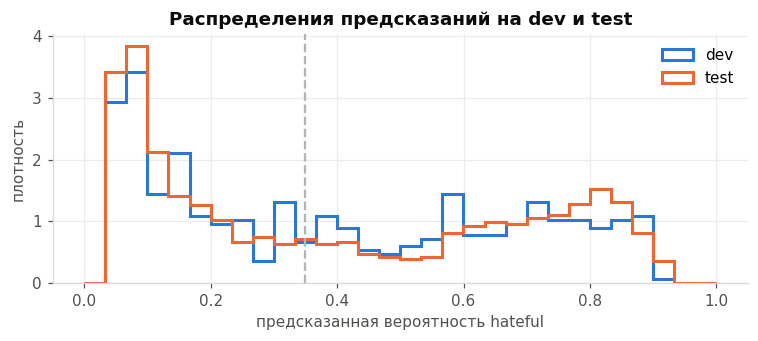

In [34]:
# сравниваю распределения предсказаний: dev и test должны выглядеть похоже
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, 1, 31)
ax.hist(best_probs, bins=bins, histtype="step", linewidth=2, color=C_BLUE,
        density=True, label="dev")
ax.hist(test_probs, bins=bins, histtype="step", linewidth=2, color=C_ORANGE,
        density=True, label="test")
ax.axvline(THRESHOLD, color="#b5b5b0", linestyle="--", linewidth=1.5)
ax.set_xlabel("предсказанная вероятность hateful")
ax.set_ylabel("плотность")
ax.set_title("Распределения предсказаний на dev и test")
ax.legend()
tidy(ax)
plt.tight_layout()
plt.show()

---
## 15. Выводы

In [35]:
display(results_df)

base_auc = results_df.loc[[i for i in results_df.index if i.startswith("Бейзлайн")][0], "roc_auc"]
best_auc = results_df.iloc[0]["roc_auc"]
print(f"бейзлайн (подход ноутбука 1): AUROC {base_auc:.3f}")
print(f"лучшая совместная модель:     AUROC {best_auc:.3f}")
print(f"прирост:                      {best_auc - base_auc:+.3f}")
print()
print("напоминание про масштаб: dev это 500 примеров, доверительный интервал у AUROC")
print("примерно ±0.04, так что разницу меньше этой величины считать значимой нельзя")

,roc_auc,accuracy,f1,macro_f1
опыт,,,,
Бейзлайн: склейка векторов + MLP (подход ноутбука 1),0.690,0.600,0.479,0.577
"A. Взаимное внимание, CLIP заморожен",0.679,0.616,0.570,0.611
B. Взаимное внимание + дообучение CLIP,0.678,0.610,0.562,0.605
C2. Многозадачное обучение на обоих датасетах,0.664,0.620,0.656,0.616
"C1. Предобучение на Memotion, затем hateful",0.629,0.606,0.610,0.606


бейзлайн (подход ноутбука 1): AUROC 0.690
лучшая совместная модель:     AUROC 0.690
прирост:                      +0.000

напоминание про масштаб: dev это 500 примеров, доверительный интервал у AUROC
примерно ±0.04, так что разницу меньше этой величины считать значимой нельзя


### Про архитектуру

На этом прогоне совместная модель бейзлайн **не обогнала**. Склейка готовых векторов
с MLP дала dev AUROC 0.690, взаимное внимание с замороженным CLIP 0.679, оно же
с дообучением последних блоков CLIP 0.678. Разница меньше доверительного интервала
на 500 примерах (около ±0.04), поэтому корректная формулировка - качество неотличимо,
а не «склейка лучше».

Причину видно по кривым обучения в разделе 11: обучение шло всего 1-2 эпохи, и dev AUROC
на второй эпохе ещё растёт (опыт A: 0.654 на первой эпохе, 0.679 на второй; опыт B: 0.661
и 0.678). То есть совместная модель на момент остановки не доучена, и сравнение с полностью
сошедшимся бейзлайном для неё невыгодно. Чтобы утверждать что-то про архитектуру,
нужен прогон на 5-8 эпохах с отбором эпохи по dev.

Зато разбор ошибок в разделе 13 показывает содержательное: совместная модель исправила
70 примеров, на которых ошибся бейзлайн, и испортила 64, то есть чистый выигрыш всего
6 примеров из 500, но ошибаются две модели на **разных** примерах. Значит они видят
разное, и ансамбль из них был бы осмысленным следующим шагом.

### Про новые данные

Главный и неудобный вывод: **дополнительные данные тут не помогли**, ни через
последовательное предобучение (AUROC 0.629), ни через многозадачное обучение (0.664).
Оба варианта хуже и бейзлайна, и опыта A, который никаких новых данных не видел.

Первая причина. Разметка отвечает на другой вопрос. Тональность мема и его hate-содержание
связаны слабо, а местами противоположны: агрессивный мем часто подан как шутка
и размечен позитивно.

Вторая причина. Сама вспомогательная задача не решилась: на валидации Memotion после
одной эпохи accuracy 0.108 и macro-F1 0.065, то есть хуже случайного угадывания на трёх
классах. Переносить в основную задачу попросту нечего. Оговорка: одной эпохи на эту задачу
заведомо мало, так что это аргумент про слабость сигнала, а не доказательство.

Отрицательный результат здесь информативен: он показывает, что «добавить данных»
не универсальное лекарство, и что для переноса знаний важен не объём, а близость задачи.

Что стоило бы попробовать дальше по этой линии:

- взять датасет с близкой разметкой, например MAMI или Harmful Memes, где метки
  тоже про вредоносность, а не про настроение;
- использовать Memotion без меток вообще, как данные для дообучения CLIP на домен
  мемов контрастным способом, там разметка не нужна;
- поднять качество текста: в Memotion текст получен OCR, и часть шума идёт оттуда.

### Ограничения

- Все выводы сделаны на dev из 500 примеров, доверительный интервал AUROC около ±0.04,
  различия в третьем знаке ничего не значат.
- **Обучение шло 1-2 эпохи вместо запланированных 4-5**, потому что полный прогон
  не укладывался по времени. Кривые обучения не вышли на плато, поэтому все сравнения
  между опытами предварительные, а вывод про архитектуру не доказан ни в одну сторону.
- Каждый опыт запускался один раз, с одним сидом. Для аккуратного сравнения нужно
  несколько запусков и разброс по ним.
- Порог решения подбирался по dev, то есть под него подогнан.
- `submission_v2.csv` посчитан моделью опыта B, а не формально лучшей по таблице,
  см. оговорку в разделе 14.
